# Figure S3 and Table S1: goodness of fit of the target GMM

KDE component selection only (SIGMA default). Outputs:

- **Figure S3**: detection strata (A), QQ plots (B), KS calibrated by parametric bootstrap (C), fits per tissue (D), signature size (E, F) and sequencing depth (G)
- **Table S1**: mean target probability by number of signature genes detected, 17 tissues
- **Response numbers**: KS by condition, for tissues with at least / fewer than 250 cells

The runs reuse the v2 checkpoint: a rerun only computes missing tasks.

In [1]:
import os
import pickle
import sys
from concurrent.futures import ProcessPoolExecutor, as_completed
from contextlib import redirect_stdout
from io import StringIO
from itertools import combinations
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import kstest, norm
from sklearn.mixture import GaussianMixture

In [ ]:
PATH_SIGMA = "/mnt/projects_tn03/AD_EB_singlecell/articleSIGMA_results-2/output/results_Dominguez/merge.h5ad"
SIGMA_SCRIPTS = "/home/lemgui01/SIGMA/scripts"

FIG_DIR = "figures"
RESULTS_DIR = "results/gof"
CHECKPOINT = "results/gof/gof_runs.pkl"

# StudyCaseDominguez.conf
TARGET_GENES = ["IL7R", "PRF1", "NKG7", "CX3CR1", "GZMB", "GZMK", "CD44"]
CANDIDATE_GENES = ["CD3E", "TRAC", "CD8A", "CD8B"]
MIN_GENES_DETECTED = 3
GENE_DETECTION_THRESHOLD = 2
MIN_MEAN_EXPRESSION = 2
TARGET_SUM = 1e6
SCORE_THRESHOLD = 0.95

PREFIX = "Dominguez_science_science-abl5197_"
FOCUS = "BLD"
SMALL_N = 250

SIG_SIZES = [2, 3, 4, 5, 6]   # 7 = reference
MAX_SUBSETS = 8               # random subsets per size (all if fewer exist)
DEPTHS = [0.5, 0.25, 0.1]     # fraction of counts kept; 1 = reference
DEPTH_REPS = 3
N_BOOT_REF = 200              # bootstrap replicates for the reference fits
N_BOOT = 50                   # bootstrap replicates for the sweeps
SEED = 0
N_WORKERS = 16

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

## 1. Data loading and consistency checks

In [3]:
adata_sigma = sc.read_h5ad(PATH_SIGMA, backed="r")

In [4]:
GENES = CANDIDATE_GENES + TARGET_GENES
sub = adata_sigma[:, GENES].to_memory()


def dense(m):
    return m.toarray() if sp.issparse(m) else np.asarray(m)


# SIGMA stores raw counts in layers["raw"] and sets X to log1p-CPM (find_target.py:268)
logcpm = dense(sub.X).astype(float)
raw = dense(sub.layers["raw"]).astype(float)
assert np.allclose(raw, np.round(raw)), "layers['raw'] is not integer counts"

# Check 1: X reproduces obs['target_mean_expr']
t_idx = [GENES.index(g) for g in TARGET_GENES]
diff = np.abs(logcpm[:, t_idx].mean(axis=1) - sub.obs["target_mean_expr"].values).max()
print(f"max |mean(X[target]) - target_mean_expr| = {diff:.2e}")
assert diff < 1e-4

# Library size from any detected gene: raw / L * 1e6 = expm1(logcpm)
with np.errstate(divide="ignore", invalid="ignore"):
    lib_est = np.where(raw > 0, raw * TARGET_SUM / np.expm1(logcpm), np.nan)
lib = np.round(np.nanmedian(lib_est, axis=1))
spread = np.nanmax(np.abs(lib_est - lib[:, None]) / lib[:, None])
print(f"max relative spread of library-size estimates across genes = {spread:.2e}")
assert np.isfinite(lib).all() and spread < 1e-3

# Check 2: the prefilter reproduces the candidate set at full depth
c_idx = [GENES.index(g) for g in CANDIDATE_GENES]
assert ((raw[:, c_idx] >= GENE_DETECTION_THRESHOLD).sum(axis=1) >= MIN_GENES_DETECTED).all()

tissue = sub.obs["study"].astype(str).str.replace(PREFIX, "").str.replace("_data", "").values
TISSUES = pd.Series(tissue).value_counts().index.tolist()

max |mean(X[target]) - target_mean_expr| = 1.02e-06
max relative spread of library-size estimates across genes = 5.55e-07


## 2. Scenario builder and GMM diagnostics

In [5]:
def build_scenario(raw, lib, genes, p, rng):
    """Mean log1p-CPM over `genes` after keeping each count with probability p.

    Thinning only removes counts, so the thinned candidate set is a subset of the
    original one and re-applying the prefilter on it is exact.
    """
    if p < 1:
        raw_t = rng.binomial(raw.astype(np.int64), p).astype(float)
        rest = np.clip(lib - raw.sum(axis=1), 0, None).astype(np.int64)
        lib_t = rng.binomial(rest, p) + raw_t.sum(axis=1)
    else:
        raw_t, lib_t = raw, lib
    keep = (raw_t[:, c_idx] >= GENE_DETECTION_THRESHOLD).sum(axis=1) >= MIN_GENES_DETECTED
    g_idx = [GENES.index(g) for g in genes]
    x = np.log1p(raw_t[keep][:, g_idx] / lib_t[keep, None] * TARGET_SUM).mean(axis=1)
    n_det = (raw_t[keep][:, g_idx] > 0).sum(axis=1)
    return x, n_det, np.flatnonzero(keep)


def mixture_cdf(v, w, mu, sd):
    return np.sum(w * norm.cdf((np.asarray(v)[:, None] - mu) / sd), axis=1)


def mixture_pdf(v, w, mu, sd):
    return np.sum(w * norm.pdf((np.asarray(v)[:, None] - mu) / sd) / sd, axis=1)


def pit_ks(x, w, mu, sd):
    # Zero-mean cells get a target probability of 0 in SIGMA (find_target.py:334):
    # the fit is assessed on non-zero values, with the mixture conditioned on x > 0
    f0 = mixture_cdf([0.0], w, mu, sd)[0]
    u = np.clip((mixture_cdf(x, w, mu, sd) - f0) / (1 - f0), 1e-6, 1 - 1e-6)
    return u, kstest(u, "uniform").statistic, f0


def bootstrap_ks(w, mu, sd, n, n_boot, rng):
    """KS null distribution: data drawn from the fitted mixture, refitted with the same K."""
    out = np.empty(n_boot)
    for b in range(n_boot):
        k = rng.choice(len(w), size=n, p=w)
        xb = rng.normal(mu[k], sd[k])
        g = GaussianMixture(len(mu), means_init=mu[:, None], random_state=0).fit(xb[:, None])
        out[b] = pit_ks(np.sort(xb[xb > 0]), g.weights_, g.means_.ravel(),
                        np.sqrt(g.covariances_.ravel()))[1]
    return out


def target_probability(x_all, w, mu, sd):
    from gmm_utils import identify_target_components

    gmm = SimpleNamespace(means_=mu[:, None], covariances_=(sd ** 2)[:, None, None],
                          n_components=len(mu))
    with redirect_stdout(StringIO()):
        idx = identify_target_components(gmm, MIN_MEAN_EXPRESSION, "True")
    if np.isscalar(idx):
        return np.zeros(len(x_all)), np.array([], dtype=int)
    idx = np.atleast_1d(idx)
    dens = w * norm.pdf((x_all[:, None] - mu) / sd) / sd
    proba = dens[:, idx].sum(axis=1) / dens.sum(axis=1)
    return np.where(x_all > 0, proba, 0.0), idx


def run_one(task):
    if SIGMA_SCRIPTS not in sys.path:
        sys.path.insert(0, SIGMA_SCRIPTS)
    from gmm_utils import fit_gmm

    rng = np.random.default_rng(task["seed"])
    rows = np.flatnonzero(tissue == task["tissue"])
    x_all, n_det, keep = build_scenario(raw[rows], lib[rows], task["genes"], task["p"], rng)
    out = {k: v for k, v in task.items() if k != "seed"}
    out.update(n_cells=len(x_all), n_zero=int((x_all == 0).sum()))
    if (x_all > 0).sum() < 10:
        return out

    with redirect_stdout(StringIO()):
        gmm = fit_gmm(x_all, "kde", "Target", "False")
    if gmm is None:
        return out
    w, mu, sd = gmm.weights_, gmm.means_.ravel(), np.sqrt(gmm.covariances_.ravel())
    x = np.sort(x_all[x_all > 0])
    u, ks, f0 = pit_ks(x, w, mu, sd)
    null = bootstrap_ks(w, mu, sd, len(x_all), task["n_boot"], rng)
    idx = target_probability(x_all, w, mu, sd)[1]
    out.update(w=w, mu=mu, sd=sd, f0=f0, x=x, u=u, ks=ks, K=len(mu), target_idx=idx,
               ks_null95=np.quantile(null, 0.95), ks_p=(null >= ks).mean(),
               n_det_x=n_det[x_all > 0][np.argsort(x_all[x_all > 0])])
    return out

## 3. Runs (checkpointed)

In [6]:
rng = np.random.default_rng(SEED)
subsets = {}
for size in SIG_SIZES:
    combos = list(combinations(TARGET_GENES, size))
    pick = rng.choice(len(combos), size=min(MAX_SUBSETS, len(combos)), replace=False)
    subsets[size] = [combos[i] for i in sorted(pick)]

tasks = [{"kind": "ref", "tissue": t, "genes": tuple(TARGET_GENES), "size": 7, "p": 1.0,
          "rep": 0, "n_boot": N_BOOT_REF} for t in TISSUES]
tasks += [{"kind": "size", "tissue": t, "genes": g, "size": s, "p": 1.0, "rep": i,
           "n_boot": N_BOOT} for t in TISSUES for s in SIG_SIZES for i, g in enumerate(subsets[s])]
tasks += [{"kind": "depth", "tissue": t, "genes": tuple(TARGET_GENES), "size": 7, "p": p,
           "rep": r, "n_boot": N_BOOT} for t in TISSUES for p in DEPTHS for r in range(DEPTH_REPS)]
for i, t in enumerate(tasks):
    t["seed"] = SEED + i

key = lambda t: (t["kind"], t["tissue"], t["genes"], t["p"], t["rep"])
runs = {}
# Checkpoint written by this notebook only
if os.path.exists(CHECKPOINT):
    with open(CHECKPOINT, "rb") as f:
        runs = pickle.load(f)
todo = [t for t in tasks if key(t) not in runs]
print(f"{len(tasks)} tasks, {len(todo)} to run")

# Largest tissues first so that long tasks start early. Workers see the arrays through fork (Linux)
todo.sort(key=lambda t: -(tissue == t["tissue"]).sum())
with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
    futures = {pool.submit(run_one, t): t for t in todo}
    for i, fut in enumerate(as_completed(futures), 1):
        runs[key(futures[fut])] = fut.result()
        if i % 50 == 0 or i == len(todo):
            with open(CHECKPOINT, "wb") as f:
                pickle.dump(runs, f)
            print(f"{i}/{len(todo)} done")

833 tasks, 0 to run


In [7]:
res = pd.DataFrame([{k: r.get(k) for k in ["kind", "tissue", "size", "p", "rep", "n_cells",
                                            "K", "ks", "ks_null95", "ks_p"]}
                    for r in runs.values()])
ref = {r["tissue"]: r for r in runs.values() if r["kind"] == "ref"}
big = {t for t, r in ref.items() if "x" in r and len(r["x"]) >= SMALL_N}
res["group"] = np.where(res["tissue"].isin(big), f">= {SMALL_N} cells", f"< {SMALL_N} cells")

## 4. Table S1

In [8]:
# Table S1: mean target probability by number of signature genes detected
if SIGMA_SCRIPTS not in sys.path:
    sys.path.insert(0, SIGMA_SCRIPTS)
levels = range(1, len(TARGET_GENES) + 1)
table_s1 = []
for t, r in sorted(ref.items(), key=lambda kv: -len(kv[1].get("x", []))):
    if "mu" not in r:
        continue
    proba = target_probability(r["x"], r["w"], r["mu"], r["sd"])[0]
    by_level = pd.Series(proba).groupby(r["n_det_x"]).mean()
    table_s1.append({"tissue": t, "cells": len(r["x"]), "K": r["K"],
                     **{str(k): by_level.get(k, np.nan) for k in levels},
                     "pct_target_095": 100 * (proba >= SCORE_THRESHOLD).mean()})
table_s1 = pd.DataFrame(table_s1)
table_s1.to_csv(os.path.join(RESULTS_DIR, "table_S1.csv"), index=False)
table_s1.round(2)

,tissue,cells,K,1,2,3,4,5,6,7,pct_target_095
0,JEJEPI,12603,4,0.00,0.01,0.99,1.00,1.00,1.00,NaN,49.50
1,SPL,6355,6,0.00,0.00,0.00,0.02,0.93,1.00,1.0,29.24
2,BMA,6189,6,0.00,0.00,0.00,0.02,0.96,1.00,1.0,40.64
3,JEJLP,5449,5,0.00,0.00,0.00,0.38,0.79,0.99,NaN,0.95
4,LLN,3757,5,0.00,0.00,0.01,0.84,1.00,1.00,1.0,14.69
5,BLD,2129,5,0.00,0.00,0.03,0.97,1.00,1.00,1.0,43.12
6,LIV,1339,4,0.04,0.27,0.46,1.00,1.00,1.00,1.0,69.16
7,MLN,1315,5,0.00,0.00,0.02,0.94,1.00,1.00,1.0,21.60
8,LNG,1063,5,0.00,0.00,0.00,0.05,0.76,0.91,1.0,35.94
9,ILE,253,5,0.00,0.00,0.00,0.00,0.11,0.92,NaN,0.40


## 5. Numbers for the response

In [9]:
cond = np.select([res.kind == "ref", res.kind == "size"],
                 ["7 genes, 100%", res["size"].astype(str) + " genes"],
                 (100 * res["p"]).astype(int).astype(str) + "% counts")
order = (["7 genes, 100%"] + [f"{k} genes" for k in sorted(SIG_SIZES, reverse=True)]
         + [f"{int(100 * p)}% counts" for p in sorted(DEPTHS, reverse=True)])
cond = pd.Categorical(cond, categories=order, ordered=True)
response_numbers = (res.assign(condition=cond)
                    .groupby(["group", "condition"], observed=True)
                    .agg(runs=("ks", "size"), fitted=("ks", "count"),
                         ks_median=("ks", "median"), ks_null95_median=("ks_null95", "median"),
                         pct_rejected=("ks_p", lambda p: 100 * (p.dropna() < 0.05).mean()),
                         cells_median=("n_cells", "median"))
                    .round(3))
response_numbers.to_csv(os.path.join(RESULTS_DIR, "response_numbers.csv"))
response_numbers

runs  fitted  ks_median  ks_null95_median  \
group        condition                                                  
< 250 cells  7 genes, 100%     7       7      0.108             0.111   
             6 genes          49      49      0.112             0.104   
             5 genes          56      56      0.102             0.101   
             4 genes          56      56      0.125             0.103   
             3 genes          56      56      0.172             0.095   
             2 genes          56      56      0.305             0.106   
             50% counts       21      21      0.133             0.184   
             25% counts       21       8      0.188             0.189   
             10% counts       21       0        NaN               NaN   
>= 250 cells 7 genes, 100%    10      10      0.025             0.015   
             6 genes          70      70      0.031             0.014   
             5 genes          80      80      0.042             0.015   
             4 genes          80      80      0.085             0.017   
             3 genes          80      80      0.165             0.021   
             2 genes          80      80      0.235             0.022   
             50% counts       30      30      0.039             0.024   
             25% counts       30      30      0.098             0.063   
             10% counts       30      11      0.188             0.241   

                            pct_rejected  cells_median  
group        condition                                  
< 250 cells  7 genes, 100%        42.857          58.0  
             6 genes              40.816          58.0  
             5 genes              51.786          58.0  
             4 genes              57.143          58.0  
             3 genes              83.929          58.0  
             2 genes              98.214          58.0  
             50% counts           42.857          27.0  
             25% counts           37.500           6.0  
             10% counts              NaN           0.0  
>= 250 cells 7 genes, 100%        70.000        2961.0  
             6 genes              81.429        2961.0  
             5 genes              88.750        2961.0  
             4 genes              96.250        2961.0  
             3 genes              96.250        2961.0  
             2 genes              97.500        2961.0  
             50% counts           76.667         987.0  
             25% counts           66.667         160.0  
             10% counts           27.273           8.0

## 6. Figure S3

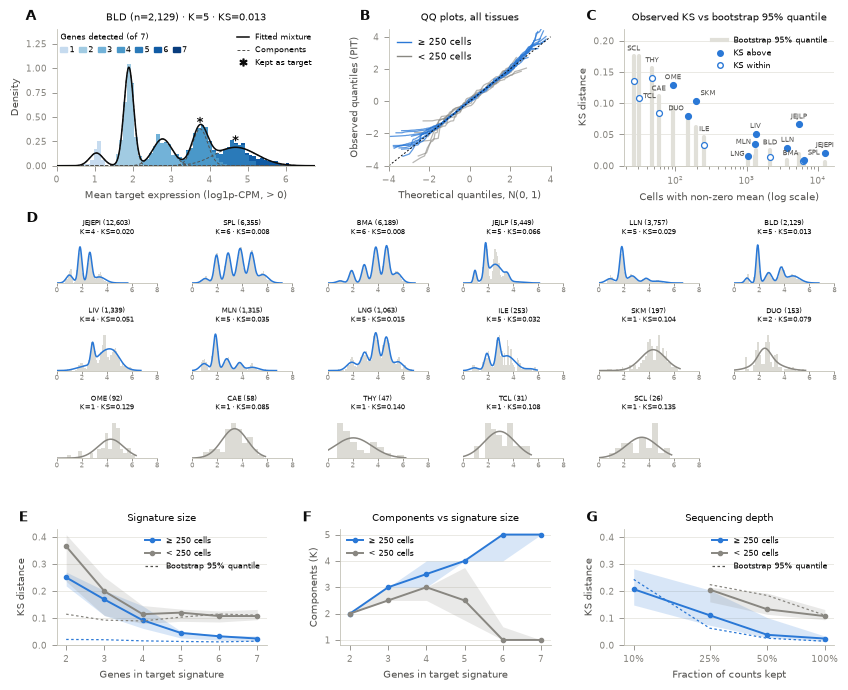

In [10]:
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, HIST = "#2a78d6", "#dcdbd5"
STRATA_CMAP = plt.get_cmap("Blues")

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.6, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.major.width": 0.6,
    "ytick.major.width": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "center", "axes.titlepad": 6, "axes.titlecolor": INK, "pdf.fonttype": 42,
})


def panel_label(ax, letter, x=-0.18, y=1.04):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=10,
            fontweight="bold", color=INK, va="bottom", ha="left")


def strata_color(k, k_max=7):
    return STRATA_CMAP(0.25 + 0.7 * (k - 1) / (k_max - 1))


def plot_strata_histogram(ax, r):
    x, n_det, w, mu, sd, f0 = r["x"], r["n_det_x"], r["w"], r["mu"], r["sd"], r["f0"]
    levels = sorted(np.unique(n_det))
    bins = np.linspace(0, x.max() * 1.02, 71)
    heights = ax.hist([x[n_det == k] for k in levels], bins=bins, stacked=True, density=True,
                      color=[strata_color(k) for k in levels], edgecolor="none")[0][-1]
    grid = np.linspace(0, bins[-1], 600)
    for k in range(len(mu)):
        ax.plot(grid, w[k] * norm.pdf(grid, mu[k], sd[k]) / (1 - f0),
                color=INK2, lw=0.7, ls=(0, (3, 2)), zorder=3)
    ax.plot(grid, mixture_pdf(grid, w, mu, sd) / (1 - f0), color=INK, lw=1.1, zorder=4)
    peak_cap = heights.max() * 1.1
    for k in r["target_idx"]:
        peak = min(w[k] * norm.pdf(mu[k], mu[k], sd[k]) / (1 - f0), peak_cap)
        ax.text(mu[k], peak, "*", ha="center", va="bottom", fontsize=9, fontweight="bold",
                color=INK, zorder=5)
    ax.set_ylim(0, heights.max() * 1.35)
    ax.set_xlim(0, bins[-1])
    ax.set_xlabel("Mean target expression (log1p-CPM, > 0)")
    ax.set_ylabel("Density")
    ax.set_title(f"{r['tissue']} (n={len(x):,}) · K={r['K']} · KS={r['ks']:.3f}")
    handles = [Patch(color=strata_color(k), label=f"{k}") for k in levels]
    leg = ax.legend(handles=handles, title=f"Genes detected (of {len(TARGET_GENES)})",
                    ncol=len(levels), loc="upper left", frameon=False, fontsize=5.5,
                    title_fontsize=5.5, handlelength=0.9, columnspacing=0.6,
                    handletextpad=0.3, borderaxespad=0.1, alignment="left")
    ax.add_artist(leg)
    ax.legend(handles=[Line2D([], [], color=INK, lw=1.1, label="Fitted mixture"),
                       Line2D([], [], color=INK2, lw=0.7, ls=(0, (3, 2)), label="Components"),
                       Line2D([], [], color=INK, marker="$*$", ms=5, lw=0, label="Kept as target")],
              loc="upper right", frameon=False, fontsize=5.5, handlelength=1.6, borderaxespad=0.1)


def plot_qq_all(ax, refs):
    for r in sorted(refs, key=lambda r: len(r["x"]) >= SMALL_N):
        z = np.sort(norm.ppf(r["u"]))
        theo = norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
        big = len(r["x"]) >= SMALL_N
        ax.plot(theo, z, color=BLUE if big else MUTED, lw=0.9, alpha=0.75 if big else 0.6)
    ax.plot([-4, 4], [-4, 4], color=INK, lw=0.7, ls=(0, (2, 2)))
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4.5)
    ax.set_xlabel("Theoretical quantiles, N(0, 1)")
    ax.set_ylabel("Observed quantiles (PIT)")
    ax.set_title("QQ plots, all tissues")
    ax.legend(handles=[Line2D([], [], color=BLUE, lw=1, label=f"≥ {SMALL_N} cells"),
                       Line2D([], [], color=MUTED, lw=1, label=f"< {SMALL_N} cells")],
              loc="upper left", frameon=False, handlelength=1.5)


# Label offsets (points) for tissues that sit close together in panel C; others go above
LABEL_POS = {"TCL": (3, -1, "left"), "DUO": (-3, 3, "right"), "SKM": (3, 3, "left"),
             "LNG": (-3, -1, "right"), "MLN": (-3, -1, "right"),
             "BMA": (-3, 3, "right"), "SPL": (3, 3, "left")}


def plot_ks_vs_n(ax, refs):
    for r in sorted(refs, key=lambda r: len(r["x"])):
        n = len(r["x"])
        ax.plot([n, n], [0, r["ks_null95"]], color=GRID, lw=3, solid_capstyle="round", zorder=1)
        ax.scatter(n, r["ks"], s=18, color=BLUE if r["ks"] > r["ks_null95"] else "white",
                   edgecolor=BLUE, linewidth=0.9, zorder=3)
        dx, dy, ha = LABEL_POS.get(r["tissue"], (0, 3, "center"))
        y = r["ks"] if r["tissue"] in LABEL_POS else max(r["ks"], r["ks_null95"])
        ax.annotate(r["tissue"], (n, y), xytext=(dx, dy), textcoords="offset points",
                    ha=ha, va="bottom", fontsize=5, color=INK2)
    top = max(max(r["ks"], r["ks_null95"]) for r in refs)
    ax.set_ylim(0, top * 1.25)
    ax.set_xscale("log")
    ax.set_xlabel("Cells with non-zero mean (log scale)")
    ax.set_ylabel("KS distance")
    ax.set_title("Observed KS vs bootstrap 95% quantile")
    ax.grid(axis="y", color=GRID, lw=0.5)
    ax.set_axisbelow(True)
    ax.legend(handles=[Line2D([], [], color=GRID, lw=3, label="Bootstrap 95% quantile"),
                       Line2D([], [], color=BLUE, marker="o", lw=0, ms=4, label="KS above"),
                       Line2D([], [], color=BLUE, marker="o", mfc="white", lw=0, ms=4,
                              label="KS within")],
              loc="upper right", frameon=False, fontsize=5.5)


def plot_tissue_grid(fig, gs_cell, refs, x_max, ncols=6):
    order = sorted(refs, key=lambda r: -len(r["x"]))
    nrows = int(np.ceil(len(order) / ncols))
    sub = gs_cell.subgridspec(nrows, ncols, hspace=0.9, wspace=0.35)
    axes = []
    for i, r in enumerate(order):
        ax = fig.add_subplot(sub[i // ncols, i % ncols])
        ax.set_xlim(0, x_max)
        ax.set_xticks(range(0, int(x_max) + 1, 2))
        ax.set_yticks([])
        ax.spines["left"].set_visible(False)
        ax.tick_params(labelsize=4.8, length=2, pad=1)
        x = r["x"]
        grid = np.linspace(0, x.max() * 1.02, 400)
        heights = ax.hist(x, bins=min(50, max(10, len(x) // 5)), density=True, color=HIST,
                          edgecolor="none")[0]
        ax.plot(grid, mixture_pdf(grid, r["w"], r["mu"], r["sd"]) / (1 - r["f0"]),
                color=BLUE if len(x) >= SMALL_N else MUTED, lw=1.1)
        ax.set_ylim(0, heights.max() * 1.3)
        ax.set_title(f"{r['tissue']} ({len(x):,})\nK={r['K']} · KS={r['ks']:.3f}",
                     fontsize=5, pad=2, linespacing=1.3)
        axes.append(ax)
    return axes


def plot_sweep(ax, kind, stat, xlabel, title, legend=True):
    d = res[(res.kind == kind) | (res.kind == "ref")].dropna(subset=["ks"]).copy()
    d["xval"] = d["size"] if kind == "size" else d["p"]
    big = set(r["tissue"] for r in ref.values() if "x" in r and len(r["x"]) >= SMALL_N)
    d["big"] = d["tissue"].isin(big)
    # One value per tissue and condition (median over subsets / replicates),
    # then median and interquartile range across tissues
    per_tissue = d.groupby(["big", "tissue", "xval"])[[stat, "ks_null95"]].median().reset_index()
    for is_big, color, label in [(True, BLUE, f"≥ {SMALL_N} cells"),
                                 (False, MUTED, f"< {SMALL_N} cells")]:
        g = per_tissue[per_tissue.big == is_big].groupby("xval")
        q = g[stat].quantile([0.25, 0.5, 0.75]).unstack()
        ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.18, lw=0)
        ax.plot(q.index, q[0.5], color=color, lw=1.4, marker="o", ms=3, label=label)
        if stat == "ks":
            null = g["ks_null95"].median()
            ax.plot(null.index, null.values, color=color, lw=0.9, ls=(0, (2, 2)))
    if stat == "ks" and legend:
        handles, _ = ax.get_legend_handles_labels()
        handles.append(Line2D([], [], color=INK2, lw=0.9, ls=(0, (2, 2)),
                              label="Bootstrap 95% quantile"))
        ax.legend(handles=handles, frameon=False, loc="upper right", fontsize=5.5)
    if stat == "ks":
        ax.set_ylabel("KS distance")
        top = ax.get_ylim()[1]
        ax.set_ylim(0, top * (1.45 if kind == "depth" else 1))
    else:
        ax.set_ylabel("Components (K)")
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.legend(frameon=False, loc="upper left", fontsize=5.5)
    if kind == "depth":
        ax.set_xscale("log")
        ticks = sorted(set(DEPTHS) | {1.0})
        ax.set_xticks(ticks)
        ax.set_xticklabels([f"{int(p * 100)}%" for p in ticks])
        ax.minorticks_off()
    else:
        ax.set_xticks(sorted(set(SIG_SIZES) | {7}))
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="y", color=GRID, lw=0.5)
    ax.set_axisbelow(True)


def make_figure():
    refs = [r for r in ref.values() if "x" in r]
    x_max = np.ceil(max(r["x"].max() for r in refs))
    ncols = 6
    nrows = int(np.ceil(len(refs) / ncols))

    fig = plt.figure(figsize=(8.5, 4.6 + 0.75 * nrows))
    gs = GridSpec(3, 1, figure=fig, height_ratios=[1.3, 0.7 * nrows, 1.1],
                  hspace=0.45, left=0.07, right=0.985, top=0.96, bottom=0.06)
    top = gs[0].subgridspec(1, 3, width_ratios=[1.6, 1, 1.3], wspace=0.35)
    bottom = gs[2].subgridspec(1, 3, wspace=0.35)

    ax = fig.add_subplot(top[0, 0]); plot_strata_histogram(ax, ref[FOCUS]); panel_label(ax, "A", x=-0.12)
    ax = fig.add_subplot(top[0, 1]); plot_qq_all(ax, refs); panel_label(ax, "B")
    ax = fig.add_subplot(top[0, 2]); plot_ks_vs_n(ax, refs); panel_label(ax, "C")

    axes = plot_tissue_grid(fig, gs[1], refs, x_max, ncols)
    panel_label(axes[0], "D", x=-0.3, y=1.25)

    ax = fig.add_subplot(bottom[0, 0])
    plot_sweep(ax, "size", "ks", "Genes in target signature", "Signature size")
    panel_label(ax, "E")
    ax = fig.add_subplot(bottom[0, 1])
    plot_sweep(ax, "size", "K", "Genes in target signature", "Components vs signature size")
    panel_label(ax, "F")
    ax = fig.add_subplot(bottom[0, 2])
    plot_sweep(ax, "depth", "ks", "Fraction of counts kept", "Sequencing depth")
    panel_label(ax, "G")
    return fig


fig = make_figure()
fig.savefig(os.path.join(FIG_DIR, "figure_S3.pdf"), bbox_inches="tight", dpi=500)
fig.savefig(os.path.join(FIG_DIR, "figure_S3.png"), bbox_inches="tight", dpi=200)
plt.show()